<!-- @format -->

# Vanilla GAN


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

while not (
    (PROJECT_ROOT / "data_loader.py").is_file()
    and (PROJECT_ROOT / "models" / "mlp_classifier.py").is_file()
):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not locate the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")


Project root: D:\Main\sem5\deep-learning\ASG_2


In [2]:
import json
import time
import matplotlib.pyplot as plt
import torch
from torch import nn, optim

from data_loader import get_dataloaders
from utils.paths import (
    CHECKPOINT_DIR,
    DATA_DIR,
    FIGURES_DIR,
    METRICS_DIR,
    ensure_results_dirs,
    get_device,
)
from utils.reproducibility import set_seed

SEED = 42
BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 0.001
LATENT_DIM = 100

DEVICE = get_device()

set_seed(SEED)
ensure_results_dirs()

print(f"Device: {DEVICE}")


Device: xpu


In [3]:
train_loader, val_loader, test_loader = get_dataloaders(batch_size=BATCH_SIZE)

print(f"Training batches:   {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Testing batches:    {len(test_loader)}")

images, labels = next(iter(train_loader))

print(f"\nImage shape: {images.shape}")
print(f"Pixel range: [{images.min().item():.4f}, {images.max().item():.4f}]")


Training batches:   438
Validation batches: 55
Testing batches:    55

Image shape: torch.Size([128, 1, 28, 28])
Pixel range: [0.0000, 1.0000]


In [4]:
from models.vanilla_gan import build_generator, build_discriminator

generator = build_generator(latent_dim=LATENT_DIM).to(DEVICE)
discriminator = build_discriminator().to(DEVICE)

print(generator)
print(discriminator)


Sequential(
  (0): Linear(in_features=100, out_features=256, bias=True)
  (1): LeakyReLU(negative_slope=0.2, inplace=True)
  (2): Linear(in_features=256, out_features=512, bias=True)
  (3): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (4): LeakyReLU(negative_slope=0.2, inplace=True)
  (5): Linear(in_features=512, out_features=1024, bias=True)
  (6): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (7): LeakyReLU(negative_slope=0.2, inplace=True)
  (8): Linear(in_features=1024, out_features=784, bias=True)
  (9): Tanh()
  (10): Unflatten(dim=1, unflattened_size=(1, 28, 28))
)
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): LeakyReLU(negative_slope=0.2, inplace=True)
  (3): Linear(in_features=512, out_features=256, bias=True)
  (4): LeakyReLU(negative_slope=0.2, inplace=True)
  (5): Linear(in_features=256, out_features=1, bi

In [7]:
noise = torch.randn(BATCH_SIZE, LATENT_DIM).to(DEVICE)

with torch.no_grad():
    fake_images = generator(noise)
    discriminator_output = discriminator(fake_images)

print(f"Noise shape: {noise.shape}")
print(f"Generated images shape: {fake_images.shape}")
print(
    f"Generated pixel range: [{fake_images.min().item():.4f}, {fake_images.max().item():.4f}]"
)
print(f"Discriminator output shape: {discriminator_output.shape}")


Noise shape: torch.Size([128, 100])
Generated images shape: torch.Size([128, 1, 28, 28])
Generated pixel range: [-0.9725, 0.9606]
Discriminator output shape: torch.Size([128, 1])


In [8]:
criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE,
    betas=(0.5, 0.999),
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE,
    betas=(0.5, 0.999),
)


In [9]:
real_label = 1.0
fake_label = 0.0

print(f"Real label: {real_label}")
print(f"Fake label: {fake_label}")


Real label: 1.0
Fake label: 0.0


In [10]:
history = {
    "generator_loss": [],
    "discriminator_loss": [],
}

start_time = time.time()

for epoch in range(EPOCHS):
    generator.train()
    discriminator.train()

    total_g_loss = 0.0
    total_d_loss = 0.0
    total_samples = 0

    for real_images, _ in train_loader:
        real_images = real_images.to(DEVICE)
        real_images = real_images * 2 - 1

        batch_size = real_images.size(0)

        real_targets = torch.ones(batch_size, 1, device=DEVICE)
        fake_targets = torch.zeros(batch_size, 1, device=DEVICE)

        # Train Discriminator
        optimizer_D.zero_grad()

        real_outputs = discriminator(real_images)
        d_real_loss = criterion(real_outputs, real_targets)

        noise = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
        fake_images = generator(noise)

        fake_outputs = discriminator(fake_images.detach())
        d_fake_loss = criterion(fake_outputs, fake_targets)

        d_loss = d_real_loss + d_fake_loss
        d_loss.backward()
        optimizer_D.step()

        # Train Generator
        optimizer_G.zero_grad()

        noise = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
        generated_images = generator(noise)

        generated_outputs = discriminator(generated_images)
        g_loss = criterion(generated_outputs, real_targets)

        g_loss.backward()
        optimizer_G.step()

        total_g_loss += g_loss.item() * batch_size
        total_d_loss += d_loss.item() * batch_size
        total_samples += batch_size

    avg_g_loss = total_g_loss / total_samples
    avg_d_loss = total_d_loss / total_samples

    history["generator_loss"].append(avg_g_loss)
    history["discriminator_loss"].append(avg_d_loss)

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"| G Loss: {avg_g_loss:.4f} "
        f"| D Loss: {avg_d_loss:.4f} "
        f"| Elapsed: {elapsed:.2f}s"
    )


Epoch [1/30] | G Loss: 2.1730 | D Loss: 1.0321 | Elapsed: 15.58s
Epoch [2/30] | G Loss: 1.6107 | D Loss: 1.1403 | Elapsed: 27.44s
Epoch [3/30] | G Loss: 1.1253 | D Loss: 1.2566 | Elapsed: 38.63s
Epoch [4/30] | G Loss: 1.0323 | D Loss: 1.2739 | Elapsed: 50.81s
Epoch [5/30] | G Loss: 1.0114 | D Loss: 1.2774 | Elapsed: 61.38s
Epoch [6/30] | G Loss: 0.9950 | D Loss: 1.2832 | Elapsed: 74.17s
Epoch [7/30] | G Loss: 0.9927 | D Loss: 1.2866 | Elapsed: 85.41s
Epoch [8/30] | G Loss: 0.9647 | D Loss: 1.2972 | Elapsed: 100.58s
Epoch [9/30] | G Loss: 0.9659 | D Loss: 1.2979 | Elapsed: 111.46s
Epoch [10/30] | G Loss: 0.9393 | D Loss: 1.3075 | Elapsed: 123.18s
Epoch [11/30] | G Loss: 0.9310 | D Loss: 1.3082 | Elapsed: 134.43s
Epoch [12/30] | G Loss: 0.9283 | D Loss: 1.3147 | Elapsed: 147.19s
Epoch [13/30] | G Loss: 0.9092 | D Loss: 1.3188 | Elapsed: 164.10s
Epoch [14/30] | G Loss: 0.9028 | D Loss: 1.3196 | Elapsed: 178.42s
Epoch [15/30] | G Loss: 0.8915 | D Loss: 1.3249 | Elapsed: 196.70s
Epoch [16/3

In [11]:
checkpoint = {
    "generator_state_dict": generator.state_dict(),
    "discriminator_state_dict": discriminator.state_dict(),
    "optimizer_G_state_dict": optimizer_G.state_dict(),
    "optimizer_D_state_dict": optimizer_D.state_dict(),
    "latent_dim": LATENT_DIM,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "history": history,
}

checkpoint_path = CHECKPOINT_DIR / "vanilla_gan_best.pth"

torch.save(checkpoint, checkpoint_path)

print(f"Checkpoint saved: {checkpoint_path}")


Checkpoint saved: D:\Main\sem5\deep-learning\ASG_2\results\checkpoints\vanilla_gan_best.pth


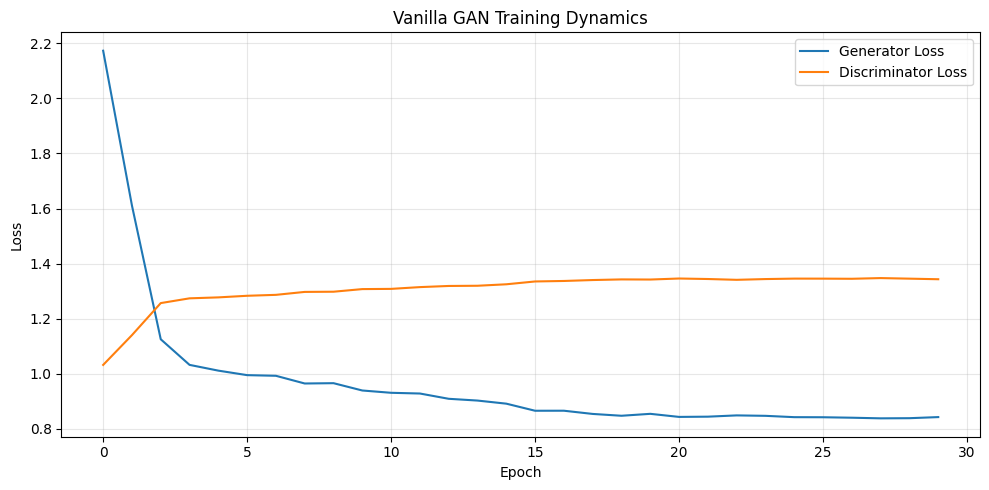

Figure saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\vanilla_gan_training_curves.png


In [12]:
plt.figure(figsize=(10, 5))

plt.plot(history["generator_loss"], label="Generator Loss")
plt.plot(history["discriminator_loss"], label="Discriminator Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Vanilla GAN Training Dynamics")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

figure_path = FIGURES_DIR / "vanilla_gan_training_curves.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved: {figure_path}")


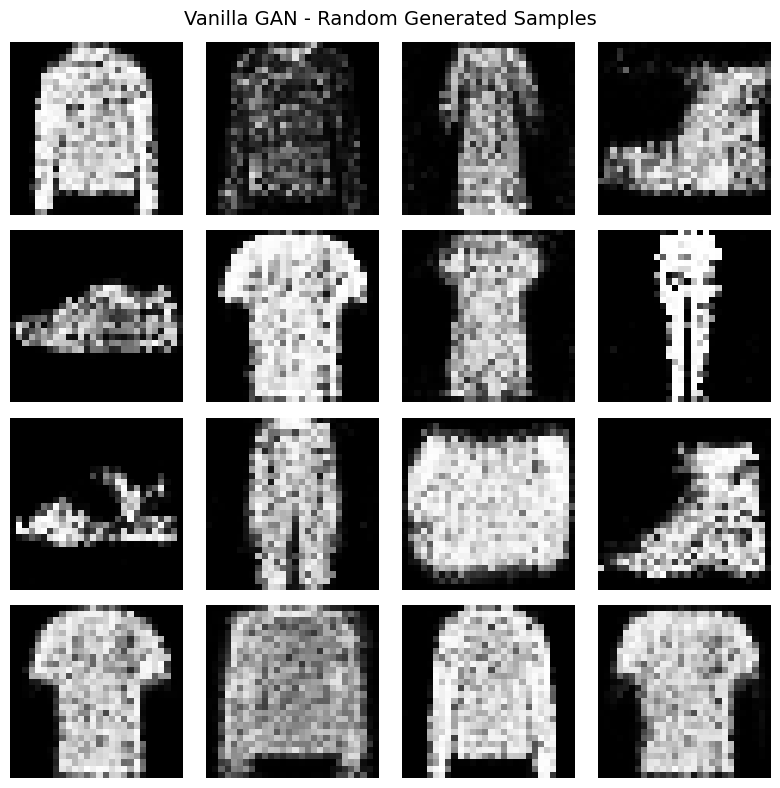

Generated samples shape: torch.Size([16, 1, 28, 28])
Figure saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\vanilla_gan_random_samples.png


In [13]:
generator.eval()

NUM_SAMPLES = 16

with torch.no_grad():
    noise = torch.randn(NUM_SAMPLES, LATENT_DIM, device=DEVICE)
    generated_images = generator(noise)

    # Convert pixel range from [-1, 1] to [0, 1]
    generated_images = (generated_images + 1) / 2
    generated_images = generated_images.clamp(0, 1)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for idx, ax in enumerate(axes.flat):
    ax.imshow(
        generated_images[idx].squeeze().cpu().numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.axis("off")

plt.suptitle("Vanilla GAN - Random Generated Samples", fontsize=14)
plt.tight_layout()

figure_path = FIGURES_DIR / "vanilla_gan_random_samples.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Generated samples shape: {generated_images.shape}")
print(f"Figure saved: {figure_path}")


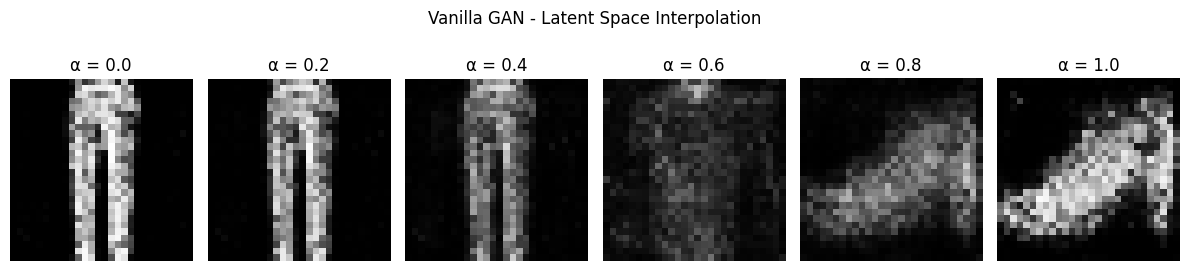

Interpolation samples: 6
Figure saved: D:\Main\sem5\deep-learning\ASG_2\results\figures\vanilla_gan_interpolation.png


In [14]:
generator.eval()

z_a = torch.randn(1, LATENT_DIM, device=DEVICE)
z_b = torch.randn(1, LATENT_DIM, device=DEVICE)

alphas = torch.linspace(0, 1, 6, device=DEVICE)

interpolated_images = []

with torch.no_grad():
    for alpha in alphas:
        z_interpolated = (1 - alpha) * z_a + alpha * z_b
        generated = generator(z_interpolated)

        generated = (generated + 1) / 2
        generated = generated.clamp(0, 1)

        interpolated_images.append(generated.squeeze().cpu())

fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for idx, ax in enumerate(axes):
    ax.imshow(
        interpolated_images[idx].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.set_title(f"α = {alphas[idx].item():.1f}")
    ax.axis("off")

plt.suptitle("Vanilla GAN - Latent Space Interpolation")
plt.tight_layout()

figure_path = FIGURES_DIR / "vanilla_gan_interpolation.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Interpolation samples: {len(interpolated_images)}")
print(f"Figure saved: {figure_path}")


In [15]:
def synchronize_device():
    if DEVICE.type == "xpu":
        torch.xpu.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()


total_training_time = elapsed
average_epoch_time = total_training_time / EPOCHS

generator.eval()

LATENCY_BATCH_SIZE = 64
latency_noise = torch.randn(
    LATENCY_BATCH_SIZE,
    LATENT_DIM,
    device=DEVICE,
)

with torch.no_grad():
    for _ in range(10):
        generator(latency_noise)

synchronize_device()
latency_start = time.perf_counter()

with torch.no_grad():
    for _ in range(100):
        generator(latency_noise)

synchronize_device()
latency_end = time.perf_counter()

inference_latency = (latency_end - latency_start) / 100

gan_metrics = {
    "model": "Vanilla GAN",
    "latent_dim": LATENT_DIM,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "total_training_time_seconds": total_training_time,
    "average_epoch_time_seconds": average_epoch_time,
    "inference_latency_batch_64_seconds": inference_latency,
    "final_generator_loss": history["generator_loss"][-1],
    "final_discriminator_loss": history["discriminator_loss"][-1],
}

metrics_path = METRICS_DIR / "vanilla_gan.json"

with open(metrics_path, "w") as file:
    json.dump(gan_metrics, file, indent=4)

print(json.dumps(gan_metrics, indent=4))
print(f"\nMetrics saved: {metrics_path}")


{
    "model": "Vanilla GAN",
    "latent_dim": 100,
    "epochs": 30,
    "batch_size": 128,
    "learning_rate": 0.001,
    "total_training_time_seconds": 405.7927987575531,
    "average_epoch_time_seconds": 13.52642662525177,
    "inference_latency_batch_64_seconds": 0.0006642240000655874,
    "final_generator_loss": 0.8427473075049264,
    "final_discriminator_loss": 1.343246992111206
}

Metrics saved: D:\Main\sem5\deep-learning\ASG_2\results\metrics\vanilla_gan.json
